# DQN

In [1]:
import sys
import torch
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

ROOT = Path.home() / "Desktop/Project_lab"
sys.path.insert(0, str(ROOT))

from src.federation import fedavg
from src.dqn import DQN

In [2]:
models = [
    {"weight": torch.tensor([1.0, 2.0])},
    {"weight": torch.tensor([3.0, 4.0])},
    {"weight": torch.tensor([5.0, 6.0])}
]

counts = [100, 200, 100]

global_model = fedavg(models, counts)

print(global_model)

assert torch.allclose(
    global_model["weight"],
    torch.tensor([3.0, 4.0])
)

print("FedAvg : test réussi")

{'weight': tensor([3., 4.])}
FedAvg : test réussi


In [3]:
rounds = sorted(
    (ROOT / "federation").glob("round_*")
)

print("Nombre de rounds :", len(rounds))

rows = []

for folder in rounds:

    global_path = folder / "global.pt"

    if not global_path.exists():
        continue

    global_weights = torch.load(
        global_path,
        map_location="cpu",
        weights_only=True
    )

    for robot in ["robot_1", "robot_2", "robot_3"]:

        local = torch.load(
            folder / f"{robot}.pt",
            map_location="cpu",
            weights_only=True
        )

        distance = sum(
            torch.sum(
                (local["weights"][key] - global_weights[key]) ** 2
            ).item()
            for key in global_weights
        ) ** 0.5

        rows.append({
            "round": int(folder.name.split("_")[-1]),
            "robot": robot,
            "weight_distance": distance,
            "local_updates": local["count"]
        })

fed_df = pd.DataFrame(rows)

display(fed_df)

Nombre de rounds : 0


""


In [5]:
import torch
import pandas as pd

from pathlib import Path

ROOT = Path.home() / "Desktop/Project_lab"

verification = []

for folder in sorted((ROOT / "federation").glob("round_*")):

    if not (folder / "global.pt").exists():
        continue

    global_weights = torch.load(
        folder / "global.pt",
        map_location="cpu",
        weights_only=True
    )

    clients = [
        torch.load(
            folder / f"robot_{i}.pt",
            map_location="cpu",
            weights_only=True
        )
        for i in range(1, 4)
    ]

    total = sum(client["count"] for client in clients)

    errors = []

    for key in global_weights:

        expected = sum(
            client["weights"][key] * client["count"] / total
            for client in clients
        )

        error = (
            expected - global_weights[key]
        ).abs().max().item()

        errors.append(error)

    verification.append({
        "round": int(folder.name.split("_")[-1]),
        "local_updates": total,
        "max_error": max(errors),
        "valid": max(errors) < 1e-6
    })

display(pd.DataFrame(verification))

,round,local_updates,max_error,valid
0,1,1492,2.980232e-08,True
1,2,2995,2.980232e-08,True
2,3,2997,5.960464e-08,True
3,4,2997,5.960464e-08,True
4,5,2994,5.960464e-08,True
5,6,2996,5.960464e-08,True
6,7,2997,5.960464e-08,True
7,8,2996,5.960464e-08,True
8,9,2997,1.192093e-07,True
9,10,2994,1.192093e-07,True


In [8]:
import seaborn as sns

files = sorted(
    (ROOT / "results").glob("*_federated_training.csv")
)

df = pd.concat(
    [pd.read_csv(f) for f in files],
    ignore_index=True
)

summary = df.groupby("robot").agg(
    transitions=("step", "count"),
    episodes=("episode", "nunique"),
    reward_mean=("reward", "mean"),
    loss_mean=("loss", "mean"),
    epsilon_final=("epsilon", "last"),
    distance_mean=("min_distance", "mean"),
    federation_round=("federation_round", "max")
)

display(summary.round(4))

,transitions,episodes,reward_mean,loss_mean,epsilon_final,distance_mean,federation_round
robot,,,,,,,
robot_1,21356,131,0.5415,1.6687,0.05,0.4802,21
robot_2,21358,144,0.6275,0.6874,0.05,0.4795,21
robot_3,21355,142,0.4447,1.0705,0.05,0.5983,21


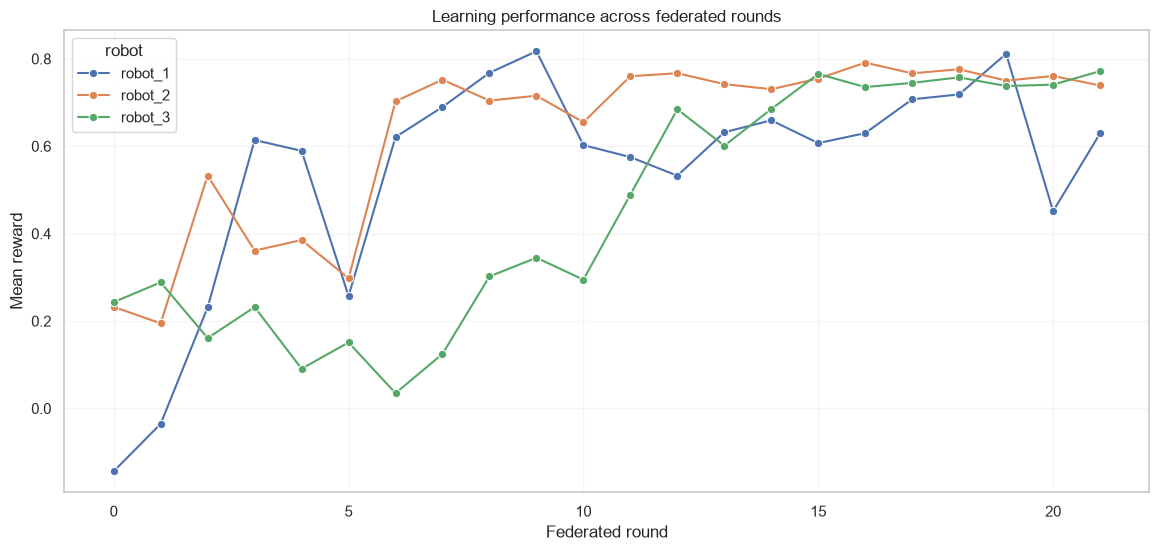

,federation_round,robot,mean_reward,mean_loss,mean_distance
0,0,robot_1,-0.1438,0.1959,0.4074
1,0,robot_2,0.2322,0.0554,0.5647
2,0,robot_3,0.2433,0.0403,0.8306
3,1,robot_1,-0.0352,0.2568,0.4373
4,1,robot_2,0.1949,0.0783,0.4206
...,...,...,...,...,...
61,20,robot_2,0.7608,0.7633,0.5097
62,20,robot_3,0.7409,1.2254,0.6911
63,21,robot_1,0.6293,2.2833,0.4878
64,21,robot_2,0.7389,0.7257,0.5119


In [9]:
round_metrics = (
    df.groupby(["federation_round", "robot"])
      .agg(
          mean_reward=("reward", "mean"),
          mean_loss=("loss", "mean"),
          mean_distance=("min_distance", "mean")
      )
      .reset_index()
)

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=round_metrics,
    x="federation_round",
    y="mean_reward",
    hue="robot",
    marker="o"
)

plt.title("Learning performance across federated rounds")
plt.xlabel("Federated round")
plt.ylabel("Mean reward")
plt.grid(alpha=0.2)
plt.show()

display(round_metrics.round(4))

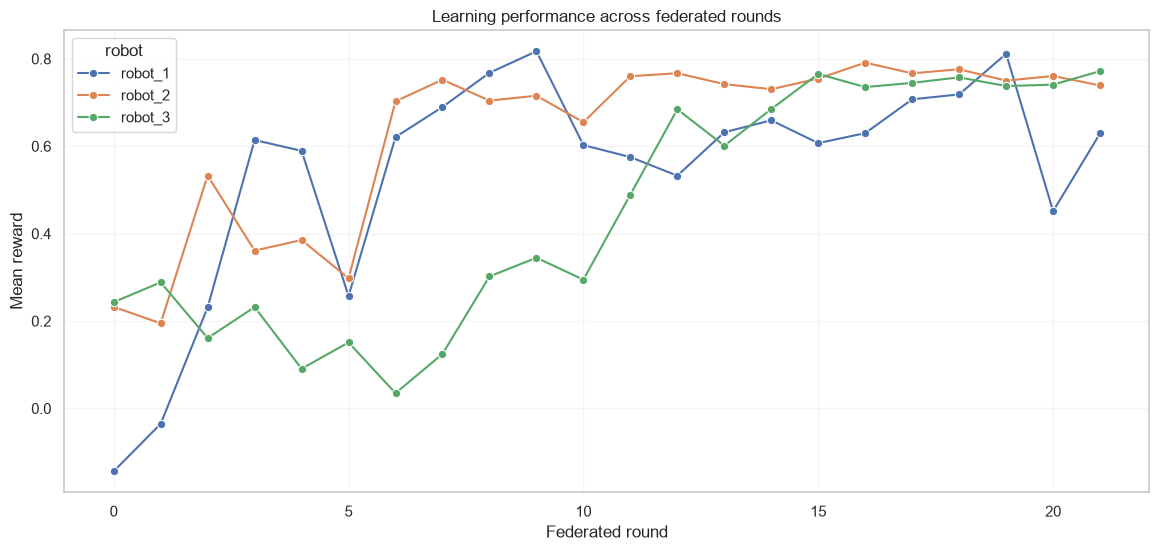

,federation_round,robot,mean_reward,mean_loss,mean_distance
0,0,robot_1,-0.1438,0.1959,0.4074
1,0,robot_2,0.2322,0.0554,0.5647
2,0,robot_3,0.2433,0.0403,0.8306
3,1,robot_1,-0.0352,0.2568,0.4373
4,1,robot_2,0.1949,0.0783,0.4206
...,...,...,...,...,...
61,20,robot_2,0.7608,0.7633,0.5097
62,20,robot_3,0.7409,1.2254,0.6911
63,21,robot_1,0.6293,2.2833,0.4878
64,21,robot_2,0.7389,0.7257,0.5119


In [10]:
round_metrics = (
    df.groupby(["federation_round", "robot"])
      .agg(
          mean_reward=("reward", "mean"),
          mean_loss=("loss", "mean"),
          mean_distance=("min_distance", "mean")
      )
      .reset_index()
)

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=round_metrics,
    x="federation_round",
    y="mean_reward",
    hue="robot",
    marker="o"
)

plt.title("Learning performance across federated rounds")
plt.xlabel("Federated round")
plt.ylabel("Mean reward")
plt.grid(alpha=0.2)
plt.show()

display(round_metrics.round(4))

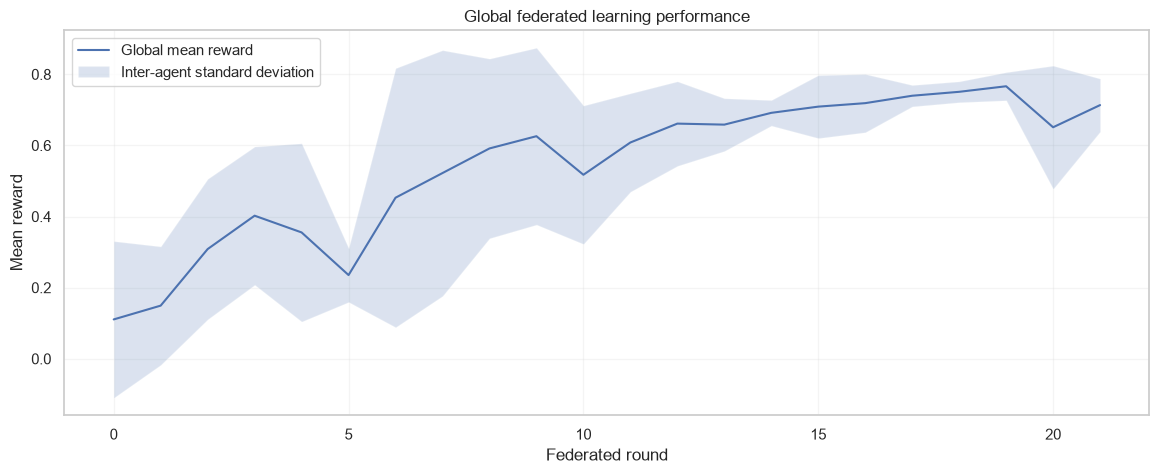

,federation_round,mean_reward,std_reward,min_reward,max_reward
0,0,0.1106,0.2203,-0.1438,0.2433
1,1,0.1494,0.1665,-0.0352,0.2885
2,2,0.3084,0.1975,0.1610,0.5329
3,3,0.4023,0.1944,0.2318,0.6141
4,4,0.3552,0.2506,0.0909,0.5895
5,5,0.2353,0.0758,0.1510,0.2978
6,6,0.4529,0.3643,0.0349,0.7028
7,7,0.5222,0.3456,0.1248,0.7521
8,8,0.5914,0.2526,0.3021,0.7679
9,9,0.6259,0.2487,0.3448,0.8172


In [11]:
global_metrics = (
    round_metrics.groupby("federation_round")
    .agg(
        mean_reward=("mean_reward", "mean"),
        std_reward=("mean_reward", "std"),
        min_reward=("mean_reward", "min"),
        max_reward=("mean_reward", "max")
    )
    .reset_index()
)

plt.figure(figsize=(14, 5))

plt.plot(
    global_metrics["federation_round"],
    global_metrics["mean_reward"],
    label="Global mean reward"
)

plt.fill_between(
    global_metrics["federation_round"],
    global_metrics["mean_reward"] - global_metrics["std_reward"],
    global_metrics["mean_reward"] + global_metrics["std_reward"],
    alpha=0.2,
    label="Inter-agent standard deviation"
)

plt.title("Global federated learning performance")
plt.xlabel("Federated round")
plt.ylabel("Mean reward")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

display(global_metrics.round(4))